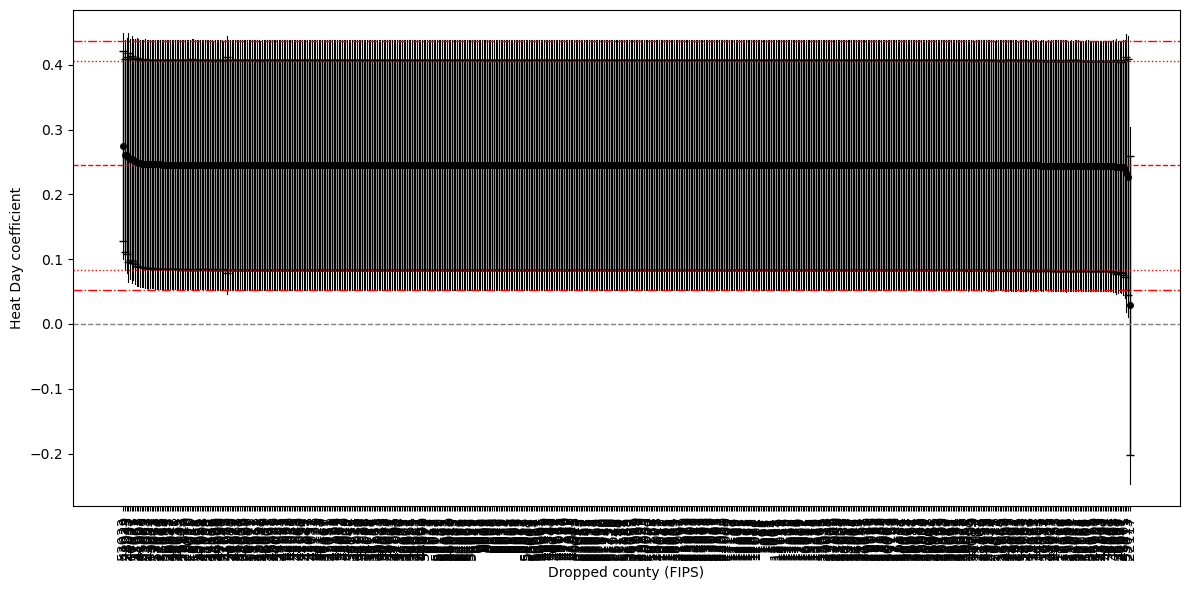

In [ ]:
# Table 2 P1 - In Out County - Plot - FIPS
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

# Directory with exported CSVs
county_in_out_directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2\Raw\FIPS"
list_of_files = []

figurename = "FIPS_Inout_LD.png"  # you can also use .pdf, .svg, etc.
output_dir = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2"
os.makedirs(output_dir, exist_ok=True)

# Loop through all CSV files in the folder
for filename in os.listdir(county_in_out_directory):
    if filename.endswith(".csv"):
        df = pd.read_csv(os.path.join(county_in_out_directory, filename))
        
        # Rename columns from the esttab-style export
        df = df.rename(columns={
            "Unnamed: 0": "Variable",
            ".": "est",
            "Unnamed: 2": "se"
        })
    
        # Try to select the 'Heat Day' row if it exists
        if "Variable" in df.columns and "hot_day" in df["Variable"].values:
            df = df[df["Variable"] == "hot_day"].reset_index(drop=True)
        else:
            # Fallback: take the third row if it exists, otherwise the last row
            if len(df) > 2:
                df = df.iloc[[2]].reset_index(drop=True)
            else:
                df = df.tail(1).reset_index(drop=True)

        df["est"] = (
            df["est"]
            .astype(str)
            .str.replace(r"[()]", "", regex=True)
            .str.strip()
        )
        df["se"] = (
            df["se"]
            .astype(str)
            .str.replace(r"[()]", "", regex=True)
            .str.strip()
        )
        df["est"] = pd.to_numeric(df["est"], errors="coerce")
        df["se"]  = pd.to_numeric(df["se"],  errors="coerce")

        # Compute 90% and 95% CIs
        df["ci90_low"]  = df["est"] - 1.645 * df["se"]
        df["ci90_high"] = df["est"] + 1.645 * df["se"]
        df["ci95_low"]  = df["est"] - 1.96  * df["se"]
        df["ci95_high"] = df["est"] + 1.96  * df["se"]

        # Extract FIPS code from filename: e.g. "baseline_strike_1001.csv" -> "1001"
        stem = os.path.splitext(filename)[0]           # "baseline_strike_1001"
        fips_code = stem.split("_")[-1]                # "1001"
        df["fips"] = fips_code

        list_of_files.append(df)

# Combine all one-out results
T2_p1_df = pd.concat(list_of_files, ignore_index=True)

# Sort by estimate
df_sorted = T2_p1_df.sort_values("est", ascending=False).reset_index(drop=True)
x = np.arange(len(df_sorted))

plt.figure(figsize=(12, 6))

# Plot 90% CI with caps
plt.errorbar(
    x=x,
    y=df_sorted["est"],
    yerr=[
        df_sorted["est"] - df_sorted["ci90_low"],
        df_sorted["ci90_high"] - df_sorted["est"]
    ],
    fmt='o',
    color='black',
    ecolor='black',
    elinewidth=0.5,
    capsize=1,
    markersize=1,
    zorder=2,
    label="95% CI"
)

# Add 95% CI as thinner lines (no caps)
for i, row in df_sorted.iterrows():
    plt.plot([i, i], [row["ci95_low"], row["ci95_high"]], color="black", linewidth=0.8)

# --- Original full-sample estimate (update these as needed) ---
orig_est = 0.245
orig_se  = 0.098
orig_ci90_low  = orig_est - 1.645 * orig_se
orig_ci90_high = orig_est + 1.645 * orig_se
orig_ci95_low  = orig_est - 1.96  * orig_se
orig_ci95_high = orig_est + 1.96  * orig_se

# Reference lines
plt.axhline(0,            color="grey", linestyle="--", linewidth=1)   # baseline
plt.axhline(orig_est,     color="red",  linestyle="--", linewidth=1)   # OG estimate
plt.axhline(orig_ci90_low,  color="red", linestyle=":",  linewidth=1)  # OG 90% CI low
plt.axhline(orig_ci90_high, color="red", linestyle=":",  linewidth=1)  # OG 90% CI high
plt.axhline(orig_ci95_low,  color="red", linestyle="-.", linewidth=1)  # OG 95% CI low
plt.axhline(orig_ci95_high, color="red", linestyle="-.", linewidth=1)  # OG 95% CI high

plt.xticks(ticks=x, labels=df_sorted["fips"], rotation=90)
plt.ylabel("Heat Day coefficient")
plt.xlabel("Dropped county (FIPS)")
plt.tight_layout()

# Save the figure
plt.savefig(os.path.join(output_dir, figurename), dpi=300, bbox_inches='tight')
plt.show()


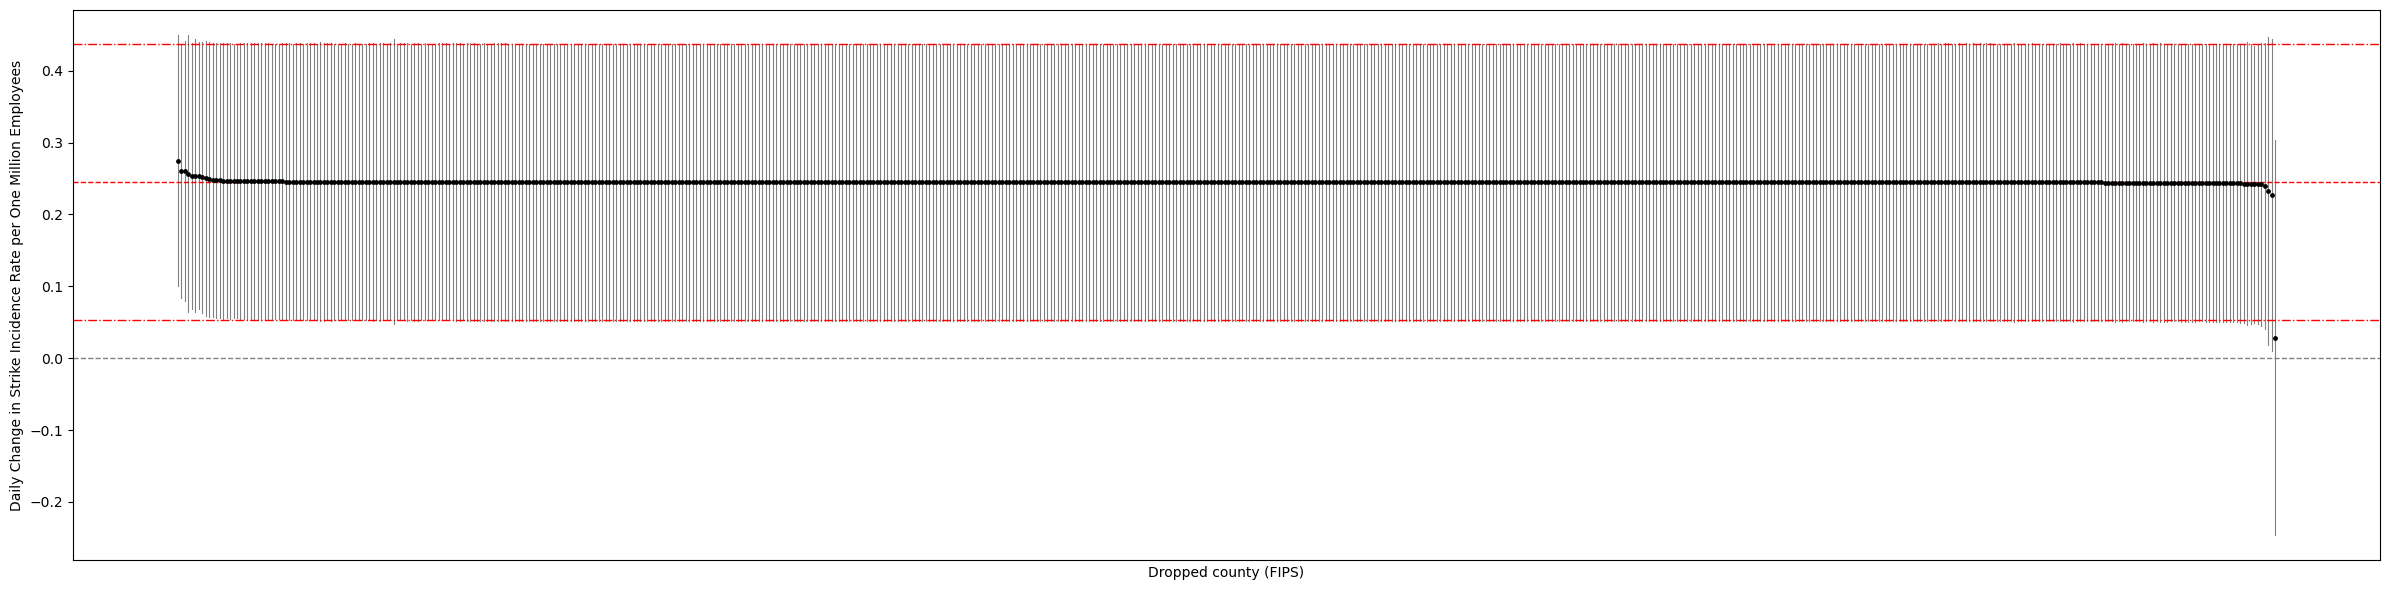

In [16]:
# Table 2 P1 - In Out County - Plot - FIPS
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

# Directory with exported CSVs
county_in_out_directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2\Raw\FIPS"
list_of_files = []

figurename = "FIPS_Inout_LD.png"
output_dir = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2"
os.makedirs(output_dir, exist_ok=True)

# -------------------------------------------------------------------
# READ & CLEAN ALL FILES
# -------------------------------------------------------------------
for filename in os.listdir(county_in_out_directory):
    if filename.endswith(".csv"):

        df = pd.read_csv(os.path.join(county_in_out_directory, filename))

        df = df.rename(columns={
            "Unnamed: 0": "Variable",
            ".": "est",
            "Unnamed: 2": "se"
        })

        # Try selecting Heat Day row
        if "Variable" in df.columns and "Heat Day" in df["Variable"].values:
            df = df[df["Variable"] == "Heat Day"].reset_index(drop=True)
        else:
            df = df.iloc[[2]] if len(df) > 2 else df.tail(1)
            df = df.reset_index(drop=True)

        # Convert est/se to numeric
        df["est"] = (
            df["est"].astype(str)
            .str.replace(r"[()]", "", regex=True)
            .str.strip()
        )
        df["se"] = (
            df["se"].astype(str)
            .str.replace(r"[()]", "", regex=True)
            .str.strip()
        )

        df["est"] = pd.to_numeric(df["est"], errors="coerce")
        df["se"]  = pd.to_numeric(df["se"],  errors="coerce")

        # --- 95% Confidence Interval ONLY ---
        df["ci95_low"]  = df["est"] - 1.96 * df["se"]
        df["ci95_high"] = df["est"] + 1.96 * df["se"]

        # Extract FIPS from filename
        stem = os.path.splitext(filename)[0]
        fips_code = stem.split("_")[-1]
        df["fips"] = fips_code

        list_of_files.append(df)

# Combine results
T2_p1_df = pd.concat(list_of_files, ignore_index=True)

# Sort by estimate
df_sorted = T2_p1_df.sort_values("est", ascending=False).reset_index(drop=True)
x = np.arange(len(df_sorted))

# -------------------------------------------------------------------
# PLOT
# -------------------------------------------------------------------
plt.figure(figsize=(24, 6))

# Plot 95% CI only (vertical line)
for i, row in df_sorted.iterrows():
    plt.plot([i, i], [row["ci95_low"], row["ci95_high"]],
             color="gray", linewidth=0.8)

# Plot point estimates
plt.scatter(x, df_sorted["est"], color="black", s=6, zorder=3)

# --- Original full-sample estimate ---
orig_est = 0.245
orig_se  = 0.098
orig_ci95_low  = orig_est - 1.96 * orig_se
orig_ci95_high = orig_est + 1.96 * orig_se

plt.axhline(0, linestyle="--", color="grey", linewidth=1)
plt.axhline(orig_est, linestyle="--", color="red", linewidth=1)
plt.axhline(orig_ci95_low, linestyle="-.", color="red", linewidth=1)
plt.axhline(orig_ci95_high, linestyle="-.", color="red", linewidth=1)

plt.xticks([], [])
plt.ylabel("Daily Change in Strike Incidence Rate per One Million Employees")
plt.xlabel("Dropped county (FIPS)")
plt.tight_layout()

plt.savefig(os.path.join(output_dir, figurename), dpi=300, bbox_inches='tight')
plt.show()



Absolute maximum DFBETA per category (normalised by full-sample SE):
          category  max_abs_dfbeta fips_at_max  beta_full  se_full  beta_drop_fips  delta_beta
3.num_above_90_60d        0.611471        6025   1.642633 0.395836        1.884675    0.242042
2.num_above_90_60d        0.586884        6071   1.029504 0.360623        0.817860   -0.211644
1.num_above_90_60d        0.420755       48453   0.451230 0.325968        0.588383    0.137153


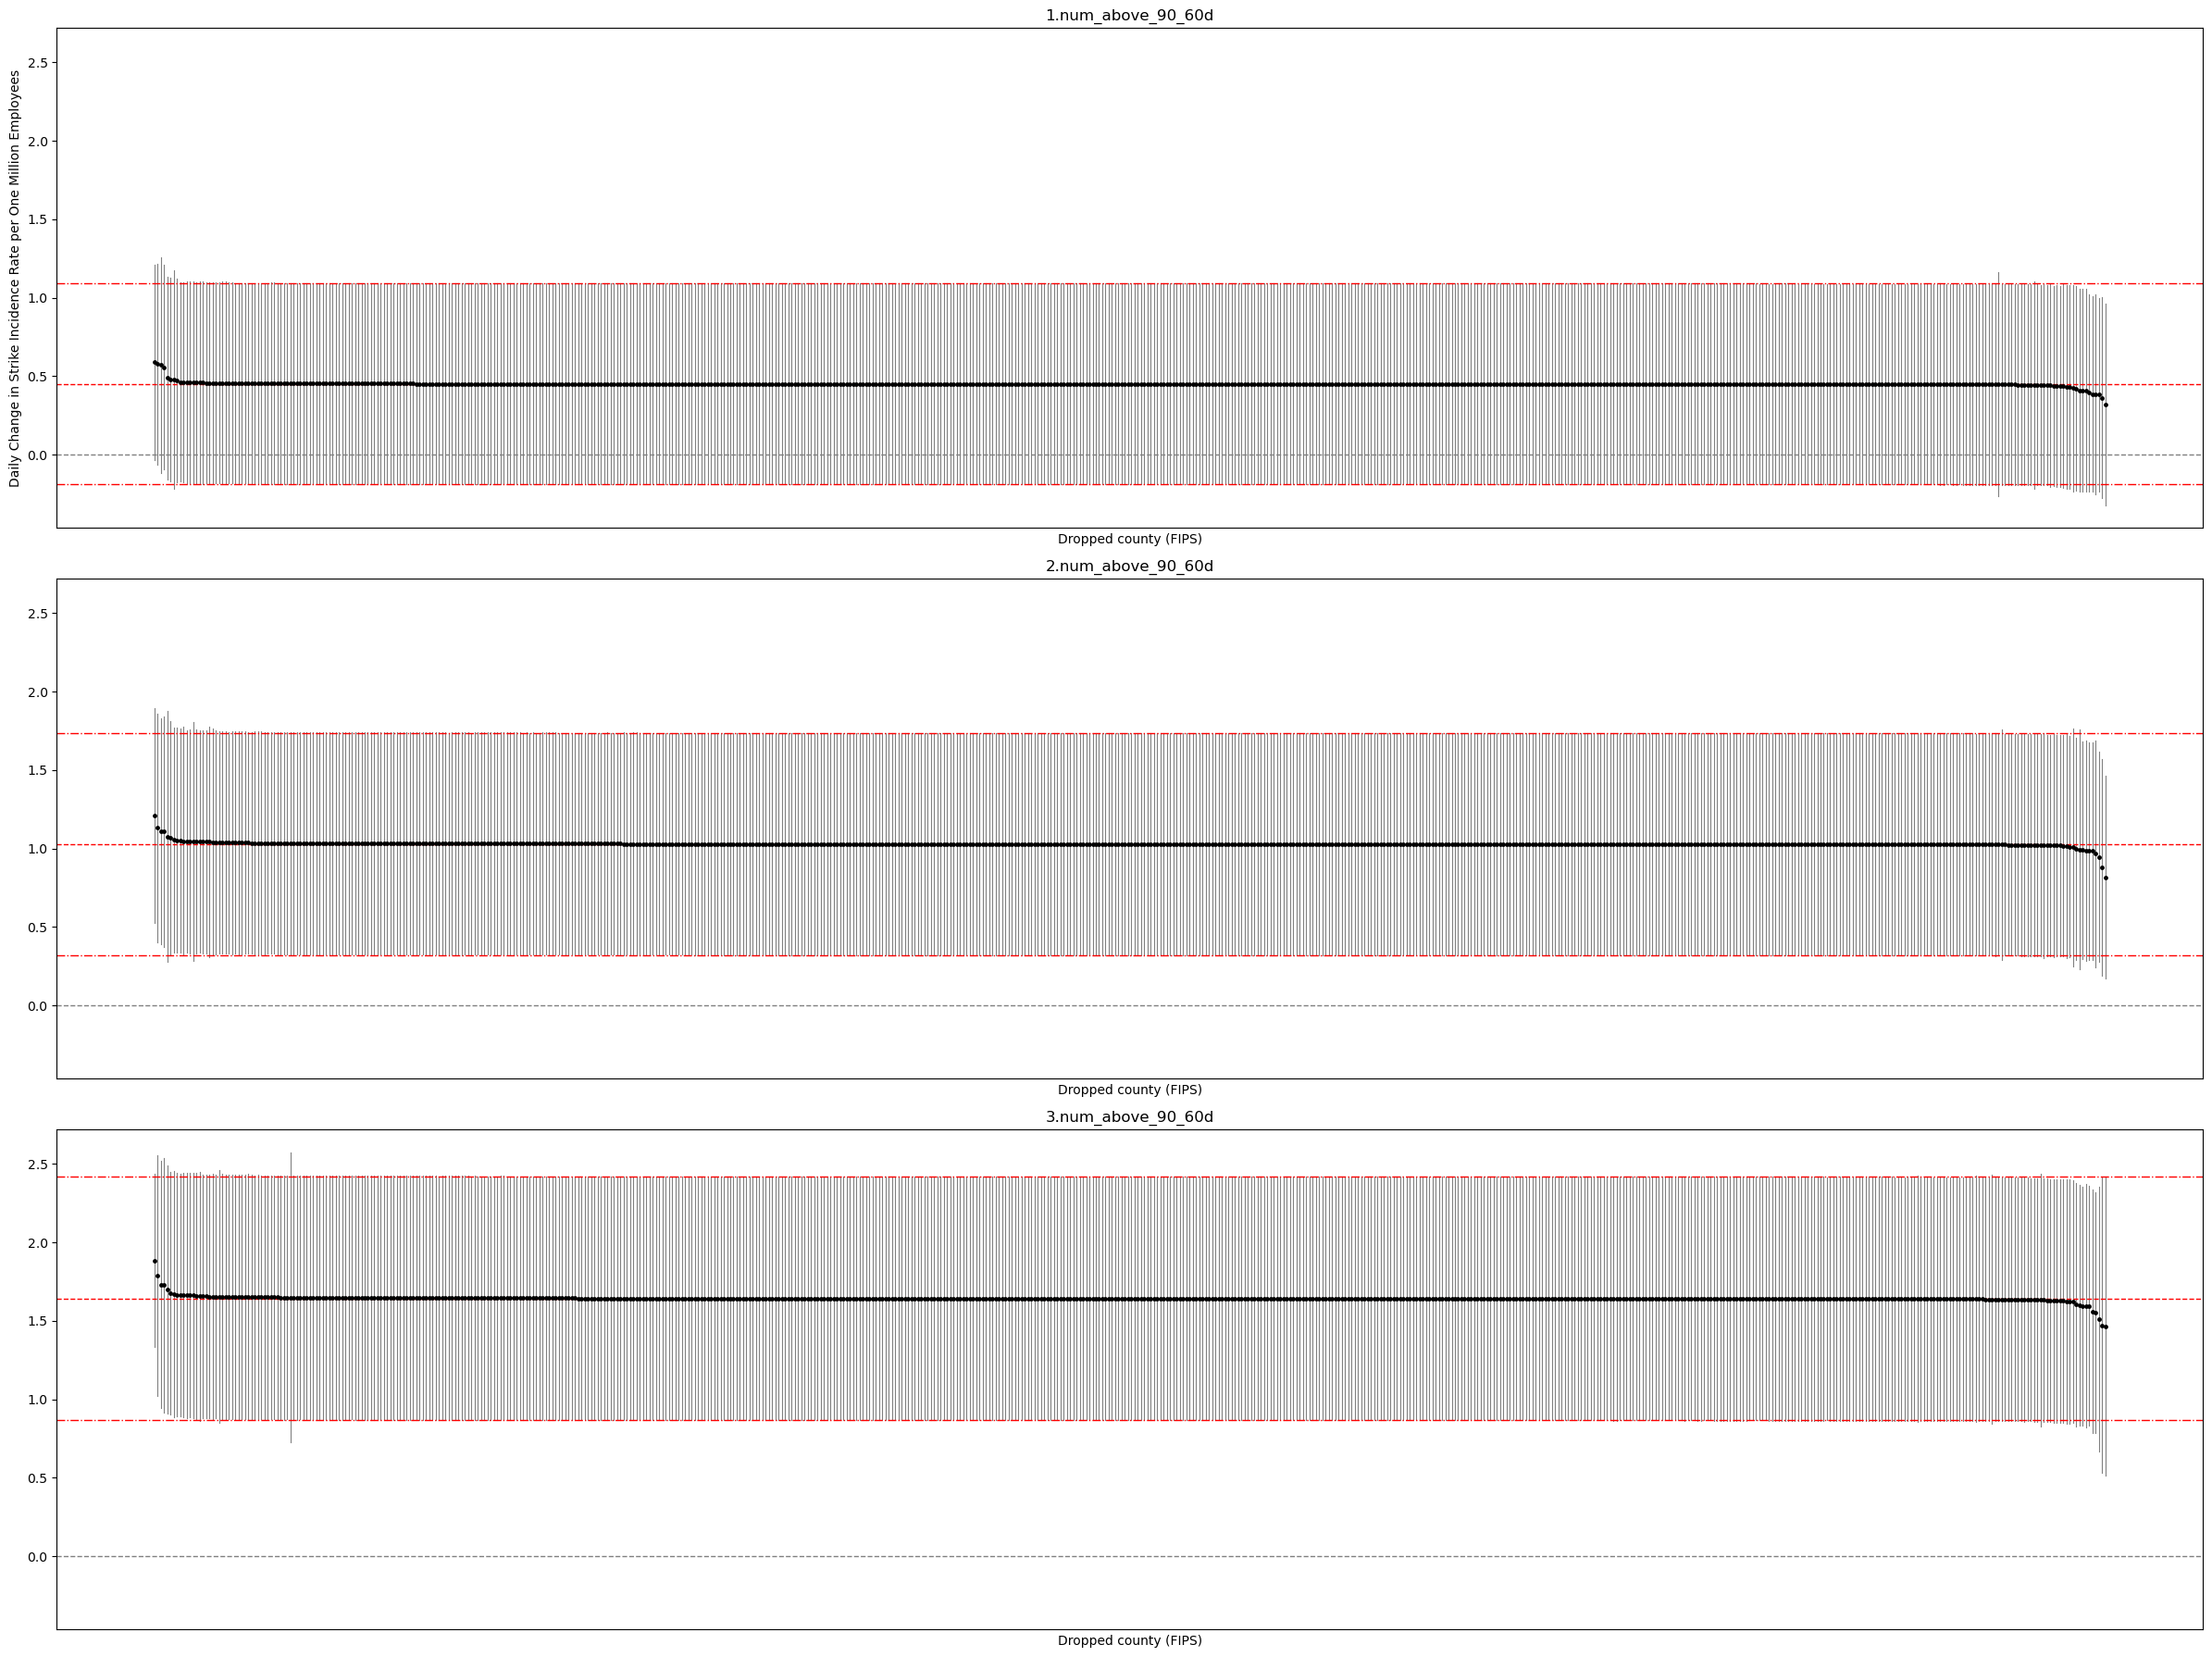

In [14]:
# ------------------------------------------------------------
# Table 2 P1 - In Out County - Plot - FIPS
# 3-panel figure: one subplot per category
# + category-specific original (full-sample) reference lines
# ------------------------------------------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# USER SETTINGS
# -----------------------------
county_in_out_directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_Jan2026\Raw\FIPS\Conflict"
output_dir = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_Jan2026"
os.makedirs(output_dir, exist_ok=True)

figurename = "FIPS_Inout_LD_3panel.png"

# Put your THREE category names here (must match what appears in the CSV 'Variable' column)
CATEGORIES = [
    "1.num_above_90_60d",  # e.g. "num_above_90_60d"
    "2.num_above_90_60d",  # e.g. "num_above_90_60d"
    "3.num_above_90_60d",  # e.g. "num_above_95_60d"
]

# Category-specific full-sample ("original") estimates and standard errors
# Fill in the est/se for each category.
ORIG_STATS = {
    "1.num_above_90_60d": {"est": 0.45123, "se": 0.3259676},
    "2.num_above_90_60d": {"est": 1.029504, "se": 0.3606228},
    "3.num_above_90_60d": {"est": 1.642633, "se": 0.3958359},
}

# If the category labels aren't reliable, force selection by row number:
# You said relevant rows are 4, 5, 6 (1-indexed) -> indices 3, 4, 5 (0-indexed)
ROW_MAP = {
    CATEGORIES[0]: 3,  # row 4
    CATEGORIES[1]: 4,  # row 5
    CATEGORIES[2]: 5,  # row 6
}


# -----------------------------
# HELPERS
# -----------------------------
def standardise_regression_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Standardise typical regression CSV export format:
    - rename columns to Variable, est, se
    - clean est/se into numeric
    """
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })

    if "Variable" not in df.columns:
        raise ValueError("Could not find/rename a 'Variable' column. Check CSV structure/headers.")
    if "est" not in df.columns or "se" not in df.columns:
        raise ValueError("Could not find/rename 'est' and 'se' columns. Check CSV structure/headers.")

    df["est"] = (
        df["est"].astype(str)
        .str.replace(r"[()]", "", regex=True)
        .str.strip()
    )
    df["se"] = (
        df["se"].astype(str)
        .str.replace(r"[()]", "", regex=True)
        .str.strip()
    )

    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df


def extract_fips_from_filename(filename: str) -> str:
    """
    Extract FIPS from filename by taking final underscore chunk before extension.
    Example: something_anything_17031.csv -> 17031
    """
    stem = os.path.splitext(os.path.basename(filename))[0]
    return stem.split("_")[-1]


def select_row_for_category(df: pd.DataFrame, category: str) -> pd.DataFrame:
    """
    Select the row for the category.
    First try exact match on Variable; if not found, force by row index using ROW_MAP.
    """
    # Try exact match first
    if category in df["Variable"].values:
        return df[df["Variable"] == category].copy().reset_index(drop=True)

    # Force by known row position (row 4/5/6 etc.)
    if category in ROW_MAP:
        idx = ROW_MAP[category]
        if idx < 0 or idx >= len(df):
            raise IndexError(
                f"ROW_MAP index {idx} out of bounds for category '{category}' "
                f"in this file (len={len(df)})."
            )
        out = df.iloc[[idx]].copy()
        out["Variable"] = category  # label it consistently for downstream steps
        return out.reset_index(drop=True)

    # If neither works, fail loudly (better than silently wrong)
    raise KeyError(
        f"Could not find category '{category}' in Variable column, and no ROW_MAP entry exists."
    )


def add_ci95(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["ci95_low"] = df["est"] - 1.96 * df["se"]
    df["ci95_high"] = df["est"] + 1.96 * df["se"]
    return df


def get_orig_lines_for_category(cat: str):
    """
    Return (orig_est, orig_ci95_low, orig_ci95_high) for a category.
    """
    if cat not in ORIG_STATS:
        raise KeyError(f"Category '{cat}' is missing from ORIG_STATS.")

    est = ORIG_STATS[cat]["est"]
    se = ORIG_STATS[cat]["se"]
    ci_low = est - 1.96 * se
    ci_high = est + 1.96 * se
    return est, ci_low, ci_high


# -----------------------------
# READ + BUILD CATEGORY DATAFRAMES
# -----------------------------
cat_to_rows = {cat: [] for cat in CATEGORIES}

for fname in os.listdir(county_in_out_directory):
    if not fname.endswith(".csv"):
        continue

    fpath = os.path.join(county_in_out_directory, fname)
    fips = extract_fips_from_filename(fname)

    raw = pd.read_csv(fpath)
    tbl = standardise_regression_table(raw)

    for cat in CATEGORIES:
        one = select_row_for_category(tbl, cat)
        one["fips"] = fips
        one = add_ci95(one)

        one = one[["Variable", "est", "se", "ci95_low", "ci95_high", "fips"]].copy()
        cat_to_rows[cat].append(one)

cat_to_df = {}
for cat in CATEGORIES:
    if len(cat_to_rows[cat]) == 0:
        cat_to_df[cat] = pd.DataFrame(columns=["Variable", "est", "se", "ci95_low", "ci95_high", "fips"])
    else:
        cat_to_df[cat] = pd.concat(cat_to_rows[cat], ignore_index=True)

# -----------------------------
# DFBETAs: absolute maximum per category
# -----------------------------
dfbeta_summary = []

for cat in CATEGORIES:
    if cat not in ORIG_STATS:
        raise KeyError(f"Category '{cat}' missing from ORIG_STATS.")

    full_est = ORIG_STATS[cat]["est"]
    full_se  = ORIG_STATS[cat]["se"]

    if full_se is None or pd.isna(full_se) or full_se == 0:
        raise ValueError(
            f"Full-sample SE for category '{cat}' is {full_se}. "
            "DFBETAs require a non-zero SE in ORIG_STATS."
        )

    df_cat = cat_to_df[cat].dropna(subset=["est", "fips"]).copy()

    # DFBETA_i = (beta_-i - beta_full) / SE_full
    df_cat["dfbeta"] = (df_cat["est"] - full_est) / full_se
    df_cat["abs_dfbeta"] = df_cat["dfbeta"].abs()

    # Absolute maximum
    idx = df_cat["abs_dfbeta"].idxmax()
    max_row = df_cat.loc[idx]

    dfbeta_summary.append({
        "category": cat,
        "max_abs_dfbeta": float(max_row["abs_dfbeta"]),
        "fips_at_max": str(max_row["fips"]),
        "beta_full": float(full_est),
        "se_full": float(full_se),
        "beta_drop_fips": float(max_row["est"]),
        "delta_beta": float(max_row["est"] - full_est),
    })

dfbeta_summary_df = pd.DataFrame(dfbeta_summary).sort_values("max_abs_dfbeta", ascending=False)

print("\nAbsolute maximum DFBETA per category (normalised by full-sample SE):")
print(dfbeta_summary_df.to_string(index=False))

# -----------------------------
# PLOT: 3 SUBPLOTS
# -----------------------------
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(24, 18), sharey=True)

for ax, cat in zip(axes, CATEGORIES):
    df_cat = cat_to_df[cat].dropna(subset=["est", "se"]).copy()

    # Sort within category
    df_sorted = df_cat.sort_values("est", ascending=False).reset_index(drop=True)
    x = np.arange(len(df_sorted))

    # CI vertical lines
    for i, row in df_sorted.iterrows():
        ax.plot([i, i], [row["ci95_low"], row["ci95_high"]], color="grey", linewidth=0.8)

    # Point estimates
    ax.scatter(x, df_sorted["est"], color="black", s=6, zorder=3)

    # Reference lines: category-specific original
    orig_est, orig_ci95_low, orig_ci95_high = get_orig_lines_for_category(cat)

    ax.axhline(0, linestyle="--", color="grey", linewidth=1)
    ax.axhline(orig_est, linestyle="--", color="red", linewidth=1)
    ax.axhline(orig_ci95_low, linestyle="-.", color="red", linewidth=1)
    ax.axhline(orig_ci95_high, linestyle="-.", color="red", linewidth=1)

    ax.set_title(cat)
    ax.set_xticks([])
    ax.set_xlabel("Dropped county (FIPS)")

axes[0].set_ylabel("Daily Change in Strike Incidence Rate per One Million Employees")

plt.tight_layout()
plt.savefig(os.path.join(output_dir, figurename), dpi=300, bbox_inches="tight")
plt.show()


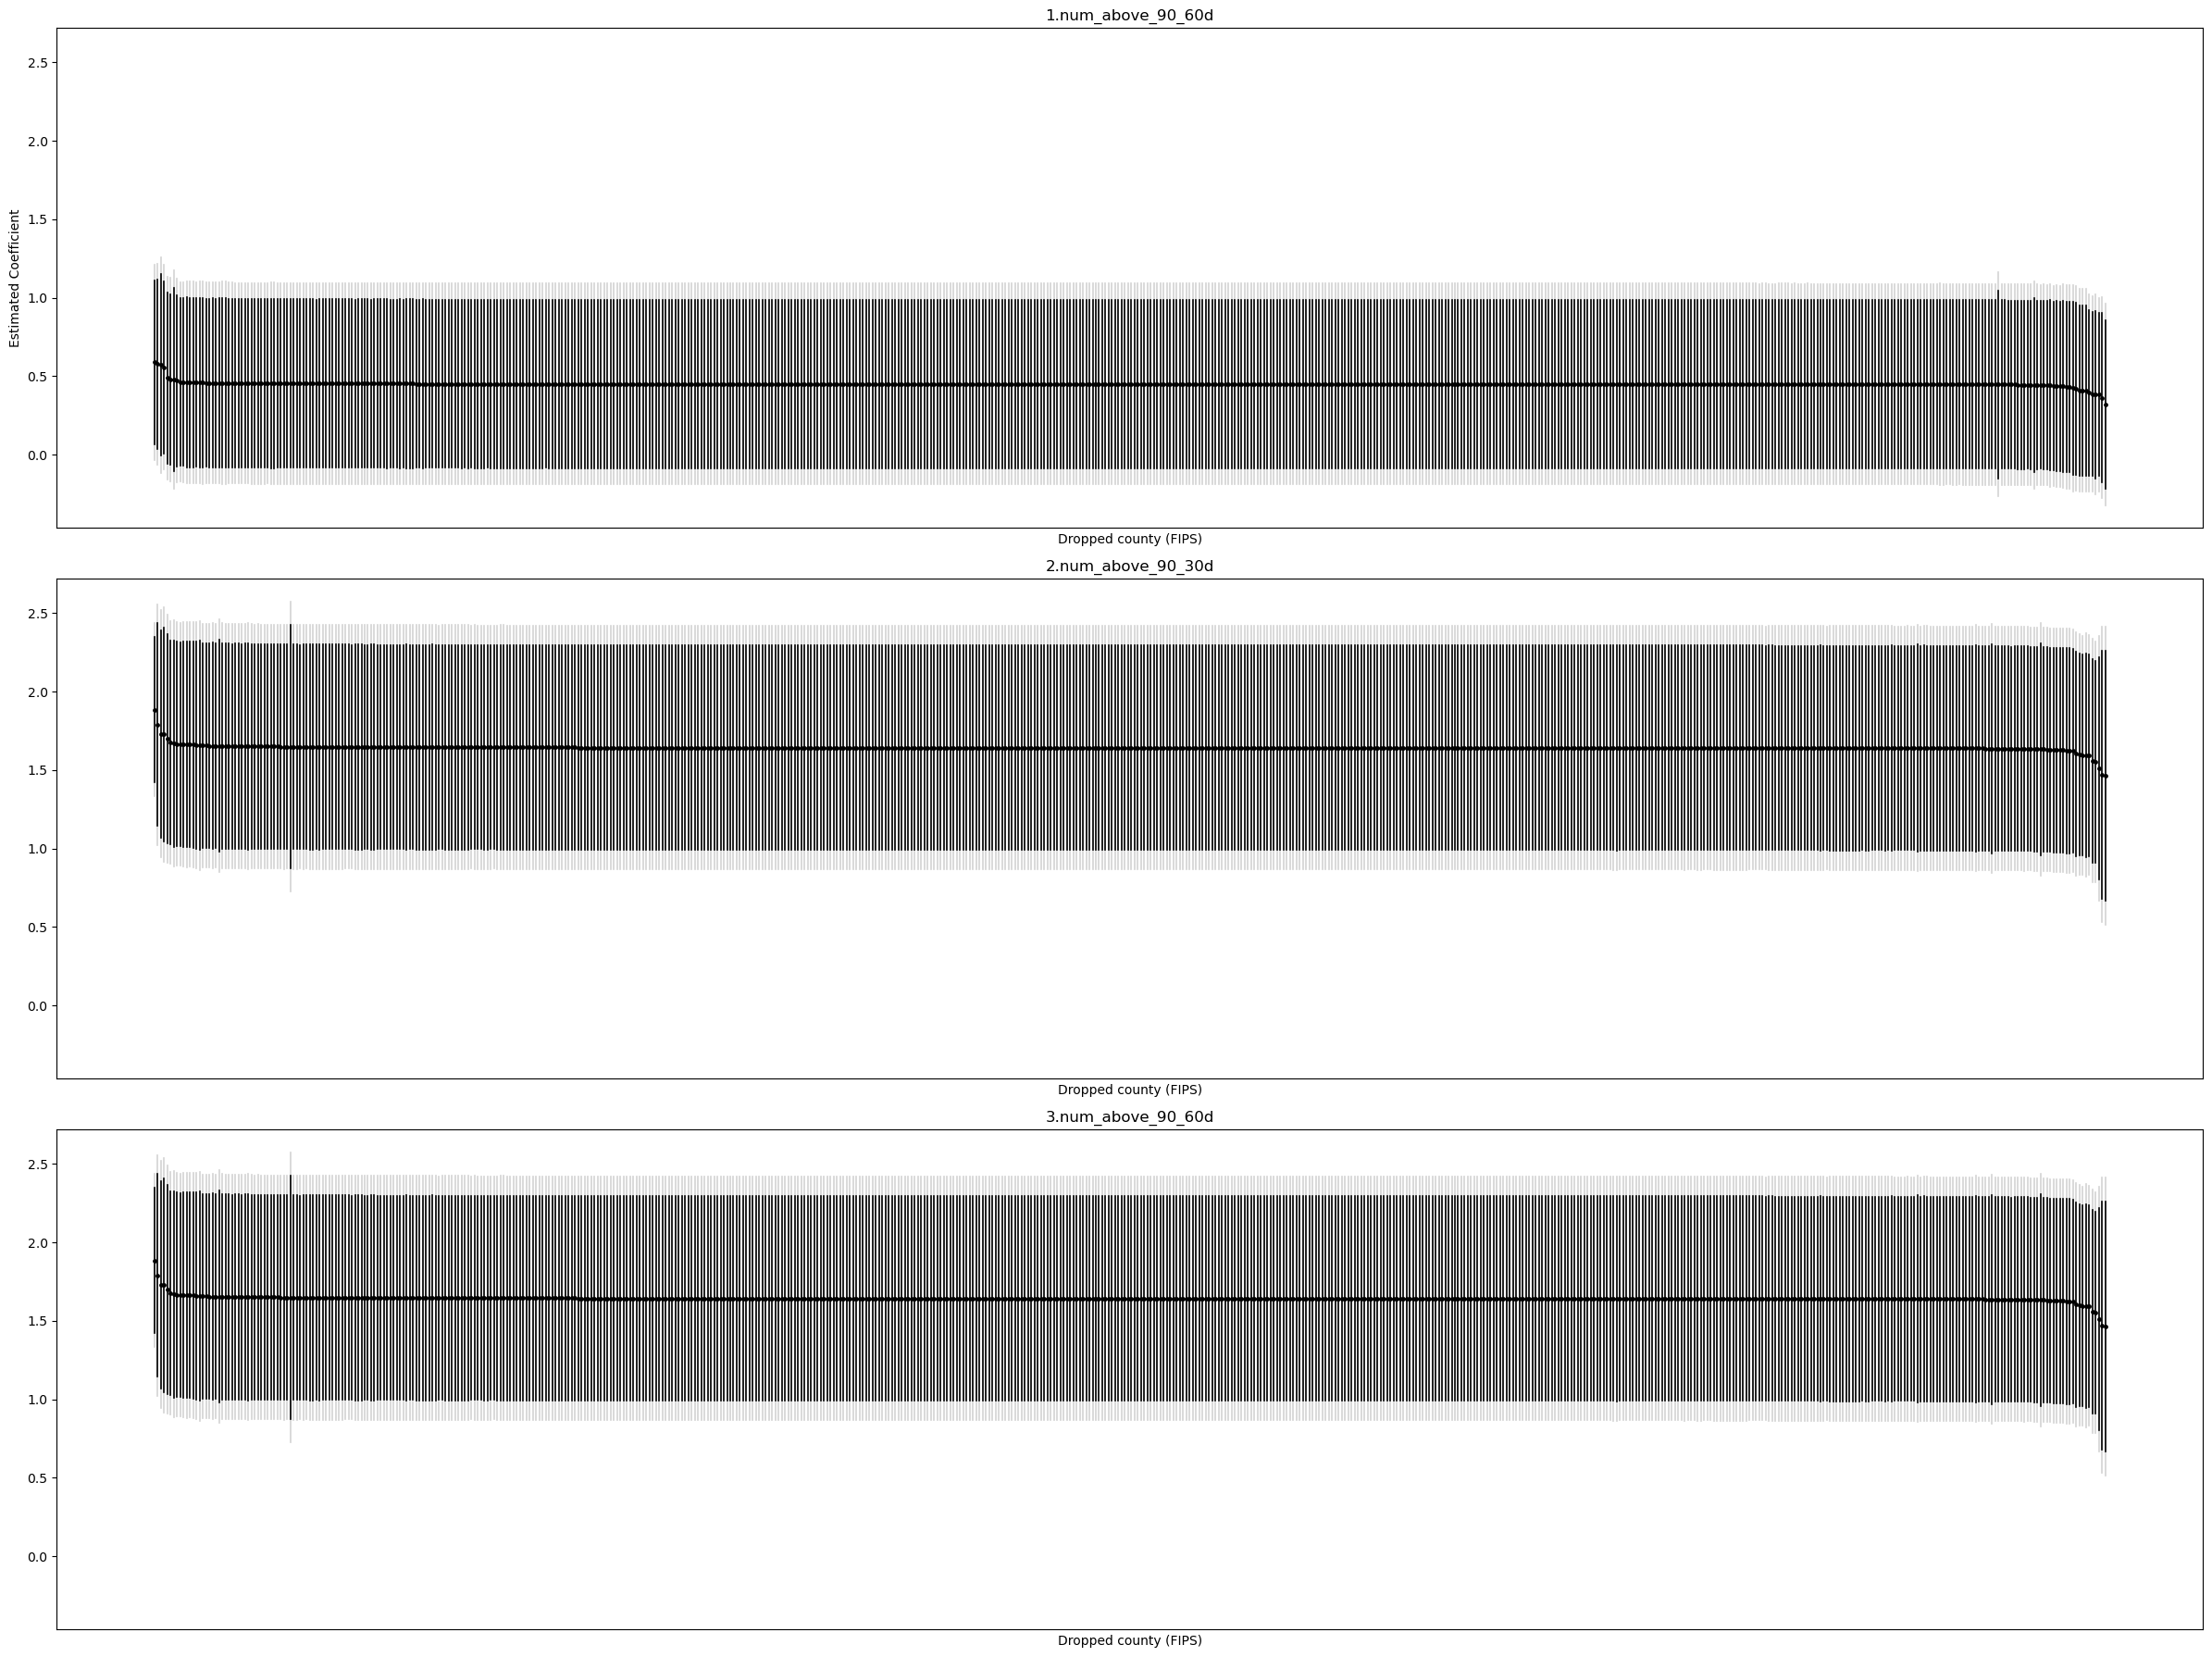

In [ ]:
# ------------------------------------------------------------
# Table 2 P1 - In Out County - Plot - FIPS
# 3-panel figure: one subplot per category
# + category-specific original (full-sample) reference lines
# + 90% and 95% CI styling:
#   - County CIs: 95% solid, 90% dashed
#   - Original CI lines: 95% solid, 90% dashed
# ------------------------------------------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# USER SETTINGS
# -----------------------------
county_in_out_directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_Jan2026\Raw\FIPS\Conflict"
output_dir = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_Jan2026"
os.makedirs(output_dir, exist_ok=True)

figurename = "FIPS_Inout_LD_3panel.png"

CATEGORIES = [
    "1.num_above_90_60d",
    "2.num_above_90_30d",
    "3.num_above_90_60d",
]

ORIG_STATS = {
    "1.num_above_90_60d": {"est": 0.45123, "se": 0.3259676},
    "2.num_above_90_30d": {"est": 1.029504, "se": 0.3606228},
    "3.num_above_90_60d": {"est": 1.642633, "se": 0.3958359},
}

# Relevant rows are 4, 5, 6 (1-indexed) -> indices 3, 4, 5 (0-indexed)
ROW_MAP = {
    CATEGORIES[0]: 3,  # row 4
    CATEGORIES[1]: 4,  # row 5
    CATEGORIES[2]: 5,  # row 6
}

# Z-values
Z_90 = 1.645
Z_95 = 1.96


# -----------------------------
# HELPERS
# -----------------------------
def standardise_regression_table(df: pd.DataFrame) -> pd.DataFrame:
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })

    if "Variable" not in df.columns:
        raise ValueError("Could not find/rename a 'Variable' column. Check CSV structure/headers.")
    if "est" not in df.columns or "se" not in df.columns:
        raise ValueError("Could not find/rename 'est' and 'se' columns. Check CSV structure/headers.")

    df["est"] = (
        df["est"].astype(str)
        .str.replace(r"[()]", "", regex=True)
        .str.strip()
    )
    df["se"] = (
        df["se"].astype(str)
        .str.replace(r"[()]", "", regex=True)
        .str.strip()
    )

    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df


def extract_fips_from_filename(filename: str) -> str:
    stem = os.path.splitext(os.path.basename(filename))[0]
    return stem.split("_")[-1]


def select_row_for_category(df: pd.DataFrame, category: str) -> pd.DataFrame:
    if category in df["Variable"].values:
        return df[df["Variable"] == category].copy().reset_index(drop=True)

    if category in ROW_MAP:
        idx = ROW_MAP[category]
        if idx < 0 or idx >= len(df):
            raise IndexError(
                f"ROW_MAP index {idx} out of bounds for category '{category}' "
                f"in this file (len={len(df)})."
            )
        out = df.iloc[[idx]].copy()
        out["Variable"] = category
        return out.reset_index(drop=True)

    raise KeyError(
        f"Could not find category '{category}' in Variable column, and no ROW_MAP entry exists."
    )


def add_cis(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["ci90_low"] = df["est"] - Z_90 * df["se"]
    df["ci90_high"] = df["est"] + Z_90 * df["se"]
    df["ci95_low"] = df["est"] - Z_95 * df["se"]
    df["ci95_high"] = df["est"] + Z_95 * df["se"]
    return df


def get_orig_lines_for_category(cat: str):
    """
    Return original estimate + (90% CI low/high) + (95% CI low/high).
    """
    if cat not in ORIG_STATS:
        raise KeyError(f"Category '{cat}' is missing from ORIG_STATS.")

    est = ORIG_STATS[cat]["est"]
    se = ORIG_STATS[cat]["se"]

    ci90_low = est - Z_90 * se
    ci90_high = est + Z_90 * se
    ci95_low = est - Z_95 * se
    ci95_high = est + Z_95 * se

    return est, ci90_low, ci90_high, ci95_low, ci95_high


# -----------------------------
# READ + BUILD CATEGORY DATAFRAMES
# -----------------------------
cat_to_rows = {cat: [] for cat in CATEGORIES}

for fname in os.listdir(county_in_out_directory):
    if not fname.endswith(".csv"):
        continue

    fpath = os.path.join(county_in_out_directory, fname)
    fips = extract_fips_from_filename(fname)

    raw = pd.read_csv(fpath)
    tbl = standardise_regression_table(raw)

    for cat in CATEGORIES:
        one = select_row_for_category(tbl, cat)
        one["fips"] = fips
        one = add_cis(one)

        one = one[[
            "Variable", "est", "se",
            "ci90_low", "ci90_high",
            "ci95_low", "ci95_high",
            "fips"
        ]].copy()

        cat_to_rows[cat].append(one)

cat_to_df = {}
for cat in CATEGORIES:
    if len(cat_to_rows[cat]) == 0:
        cat_to_df[cat] = pd.DataFrame(columns=[
            "Variable", "est", "se",
            "ci90_low", "ci90_high",
            "ci95_low", "ci95_high",
            "fips"
        ])
    else:
        cat_to_df[cat] = pd.concat(cat_to_rows[cat], ignore_index=True)


# -----------------------------
# PLOT: 3 SUBPLOTS (3 rows x 1 column)
# -----------------------------
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(24, 18), sharey=True)

for ax, cat in zip(axes, CATEGORIES):
    df_cat = cat_to_df[cat].dropna(subset=["est", "se"]).copy()

    # Sort within category
    df_sorted = df_cat.sort_values("est", ascending=False).reset_index(drop=True)
    x = np.arange(len(df_sorted))

    # Point estimates
    ax.scatter(x, df_sorted["est"], color="black", s=6, zorder=3)

    # County CIs:
    # - 95% CI: light grey (outer)
    # - 90% CI: black (inner)
    for i, row in df_sorted.iterrows():
        ax.plot(
            [i, i],
            [row["ci95_low"], row["ci95_high"]],
            color="lightgrey",
            linewidth=1.2,
            zorder=1
        )
        ax.plot(
            [i, i],
            [row["ci90_low"], row["ci90_high"]],
            color="black",
            linewidth=1.2,
            zorder=2
        )

    ax.set_title(cat)
    ax.set_xticks([])
    ax.set_xlabel("Dropped county (FIPS)")

axes[0].set_ylabel("Estimated Coefficient")

plt.tight_layout()
plt.savefig(os.path.join(output_dir, figurename), dpi=300, bbox_inches="tight")
plt.show()
